# k-means — library lab

Hands-on companion to [README §3](../../README.md#3-k-means). It uses the ready-made implementations in **scikit-learn** and **SciPy**;
the sister notebook [`kmeans_from_scratch.ipynb`](kmeans_from_scratch.ipynb) rebuilds the same algorithm in NumPy.

Part of the [clustering labs](../README.md), one folder per method: [k-means](../01-kmeans/kmeans_lab.ipynb) · [hierarchical](../02-hierarchical/hierarchical_lab.ipynb) · [DBSCAN](../03-dbscan/dbscan_lab.ipynb) · [OPTICS / HDBSCAN](../04-optics-hdbscan/optics_hdbscan_lab.ipynb) · [in practice](../05-in-practice/in_practice_lab.ipynb).

**How to use it**

1. Run the first code cell (imports and helpers). After that, run the labs in order (`Shift + Enter` cell by cell, or
   **Run All**). Labs only reuse things from earlier cells, so top-to-bottom always works.
2. Read the "How to read this" box *after* looking at the output: try to guess first.
3. Change the numbers marked `# <- try changing this` and re-run to build intuition.

**One score used everywhere:** the data in these labs comes with the "true" groups it was generated from, which a real
clustering problem doesn't have. We use them only to *grade* a result with the **adjusted Rand index (ARI)**: 1 = the
clusters match the true groups exactly, 0 = no better than random labels (it can dip slightly below 0).

| Lab | What it shows |
|---|---|
| [1](#lab-1) | how k-means moves: assign, update, repeat |
| [2](#lab-2) | why the starting centroids matter: random vs k-means++ |
| [3](#lab-3) | choosing k: elbow and silhouette |
| [4](#lab-4) | where k-means fails: six shapes and outliers |
| [Summary](#summary) | one line per lab |

Everything runs offline: the data is generated in the notebook or ships with scikit-learn.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs, make_circles, make_moons
from sklearn.metrics import adjusted_rand_score, silhouette_score


np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
SEED = 0


def plot_clusters(ax, X, labels, title, centers=None):
    """Scatter 2-D points coloured by cluster label. Label -1 (noise) is drawn as small grey crosses,
    optional `centers` as black stars."""
    labels = np.asarray(labels)
    noise = labels == -1
    ax.scatter(X[~noise, 0], X[~noise, 1], c=labels[~noise] % 10, cmap="tab10", vmin=0, vmax=9, s=12)
    if noise.any():
        ax.scatter(X[noise, 0], X[noise, 1], c="gray", marker="x", s=14, label="noise")
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], c="black", marker="*", s=200, label="centroid")
    ax.set_title(title, fontsize=10); ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2")


def make_shapes(n=500, seed=SEED):
    """The six 2-D test sets used throughout (as in scikit-learn's cluster-comparison gallery).
    Returns {name: (X, true_labels, number_of_true_clusters)}."""
    X_blob, y_blob = make_blobs(n, centers=3, random_state=seed + 170)
    X_aniso = X_blob @ np.array([[0.6, -0.6], [-0.4, 0.8]])             # stretch and shear the same blobs
    X_var, y_var = make_blobs(n, centers=3, cluster_std=[0.5, 1.5, 3.0], random_state=seed + 170)
    X_size, y_size = make_blobs([300, 150, 25], centers=[[-4, 0], [0, 0], [3.5, 0]], cluster_std=1.0,
                                random_state=seed)
    X_moon, y_moon = make_moons(n, noise=0.06, random_state=seed)
    X_circ, y_circ = make_circles(n, factor=0.45, noise=0.05, random_state=seed)
    return {"round blobs": (X_blob, y_blob, 3), "stretched blobs": (X_aniso, y_blob, 3),
            "unequal spreads": (X_var, y_var, 3), "unequal sizes": (X_size, y_size, 3),
            "moons": (X_moon, y_moon, 2), "circles": (X_circ, y_circ, 2)}


shapes = make_shapes()

<a id="lab-1"></a>

## Lab 1 · k-means, one iteration at a time

**Goal:** watch the two steps of k-means (README §3.2) repeat: **assign** every point to its nearest centroid, then
**move** every centroid to the mean of its points. The thing being minimised is the **inertia** (within-cluster sum of
squares, WCSS): the sum of squared distances from each point to its own centroid. Here the starting centroids are
picked at random, and the run is replayed one iteration at a time to draw each centroid's path.

converged after 15 iterations; inertia (sum of squared distances to own centroid) 1718.5
inertia after each iteration: [4756.7 4718.7 4686.  4665.  4642.5 4603.6 4556.6 4494.3 4421.5 4232.8
 3556.8 2360.2 1740.9 1718.5 1718.5]
points per cluster: [150 150 151 149]


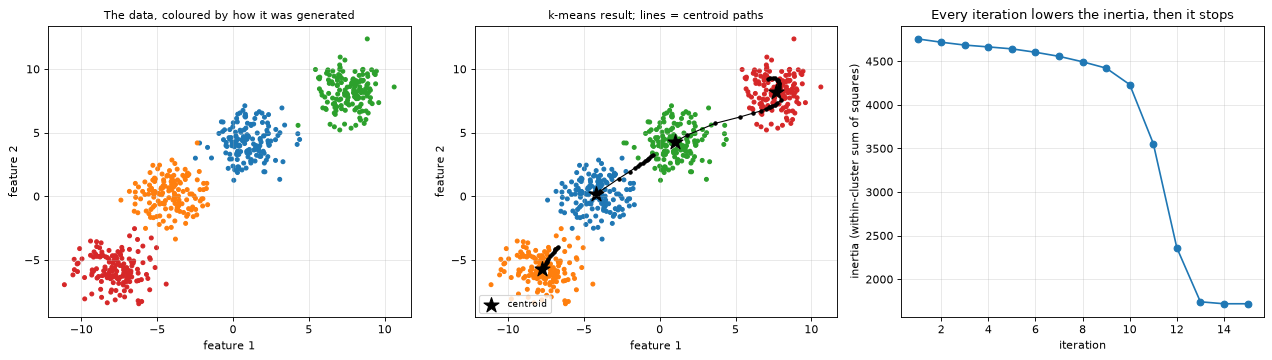

In [2]:
X1, y1 = make_blobs(600, centers=4, cluster_std=1.2, random_state=3)
final = KMeans(4, init="random", n_init=1, random_state=11).fit(X1)   # random starting centroids, run to the end
paths, inertias = [], []
for steps in range(1, final.n_iter_ + 1):                         # re-run 1, 2, ... steps from the same start
    km = KMeans(4, init="random", n_init=1, random_state=11, max_iter=steps).fit(X1)
    paths.append(km.cluster_centers_); inertias.append(km.inertia_)
paths = np.array(paths)
print(f"converged after {final.n_iter_} iterations; inertia (sum of squared distances to own centroid) {final.inertia_:.1f}")
print("inertia after each iteration:", np.round(inertias, 1))
print("points per cluster:", np.bincount(final.labels_))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
plot_clusters(axes[0], X1, y1, "The data, coloured by how it was generated")
plot_clusters(axes[1], X1, final.labels_, "k-means result; lines = centroid paths", final.cluster_centers_)
for k in range(4):
    axes[1].plot(paths[:, k, 0], paths[:, k, 1], "k.-", lw=1)
axes[1].legend(loc="lower left", fontsize=8)
axes[2].plot(range(1, final.n_iter_ + 1), inertias, marker="o")
axes[2].set_xlabel("iteration"); axes[2].set_ylabel("inertia (within-cluster sum of squares)")
axes[2].set_title("Every iteration lowers the inertia, then it stops")
plt.tight_layout(); plt.show()

> **How to read this**
> * Left: the 600 points, coloured by the blob each was generated from. Middle: the k-means result (stars) and the
>   path each centroid took (black dots, one per iteration). The final clusters hold 150 / 150 / 151 / 149 points:
>   essentially the four blobs.
> * Right: the inertia after every iteration, **4756.7 → 1718.5** in 15 iterations. It **never goes up**: the assign
>   step can only shorten each point's distance, and the mean is the point that minimises the squared distances to a
>   group (README §3.3). That is why k-means always stops.
> * The random start put **two** centroids in the top-right blob and left **one** centroid covering the two middle
>   blobs. For 10 iterations the inertia creeps down slowly (4757 → 4233) while one top-right centroid slides down
>   towards the middle; then it drops in three steps once each centroid owns one blob. A different start can stop
>   somewhere worse; that is Lab 2.

<a id="lab-2"></a>

## Lab 2 · Why the starting centroids matter: random vs k-means++

**Goal:** k-means only finds a **local** minimum of the inertia, so where it starts decides where it ends. Compare 100
random starts with 100 **k-means++** starts (README §3.4: each new starting centroid is drawn far from the ones already
chosen) on 10 blobs, and see what scikit-learn's `n_init` does.

Also refer to the from-scratch notebook's ["why the start matters" sections](kmeans_from_scratch.ipynb#toy) in order to get a deeper understanding.

random    : median inertia  1551.1, worst 10278.7, runs within 1 % of the best: 3%
k-means++ : median inertia   676.1, worst   966.3, runs within 1 % of the best: 50%

KMeans defaults (k-means++, one run): 644.8;  n_init=10 (best of 10 runs): 644.8


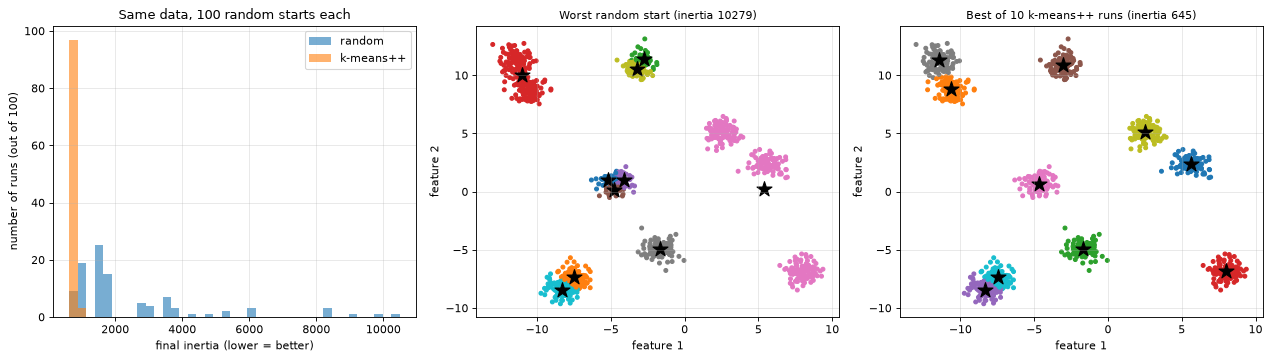

In [3]:
X2, _ = make_blobs(1000, centers=10, cluster_std=0.6, center_box=(-12, 12), random_state=42)
runs = {}
for init in ["random", "k-means++"]:
    runs[init] = np.array([KMeans(10, init=init, n_init=1, random_state=s).fit(X2).inertia_ for s in range(100)])
best = min(r.min() for r in runs.values())
for init, inertia in runs.items():
    print(f"{init:10s}: median inertia {np.median(inertia):7.1f}, worst {inertia.max():7.1f}, "
          f"runs within 1 % of the best: {np.mean(inertia <= best * 1.01):.0%}")
default = KMeans(10, random_state=0).fit(X2)                       # k-means++ and n_init="auto" (1 run for k-means++)
ten_runs = KMeans(10, n_init=10, random_state=0).fit(X2)
print(f"\nKMeans defaults (k-means++, one run): {default.inertia_:.1f};  n_init=10 (best of 10 runs): {ten_runs.inertia_:.1f}")
worst_seed = int(np.argmax(runs["random"]))
worst = KMeans(10, init="random", n_init=1, random_state=worst_seed).fit(X2)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
bins = np.linspace(best * 0.98, max(r.max() for r in runs.values()) * 1.02, 40)
for init, inertia in runs.items():
    axes[0].hist(inertia, bins=bins, alpha=0.6, label=init)
axes[0].set_xlabel("final inertia (lower = better)"); axes[0].set_ylabel("number of runs (out of 100)")
axes[0].set_title("Same data, 100 random starts each"); axes[0].legend()
plot_clusters(axes[1], X2, worst.labels_, f"Worst random start (inertia {worst.inertia_:.0f})", worst.cluster_centers_)
plot_clusters(axes[2], X2, ten_runs.labels_, f"Best of 10 k-means++ runs (inertia {ten_runs.inertia_:.0f})",
              ten_runs.cluster_centers_)
plt.tight_layout(); plt.show()

> **How to read this**
> * **Random starts** (pick 10 data points at random): median inertia **1551**, worst **10279**, and only **3 %** of
>   runs end within 1 % of the best answer. The middle plot is the worst run: some blobs share a centroid while other
>   centroids split one blob.
> * **k-means++ starts:** median **676**, worst **966**, and **50 %** of runs reach the best. Spreading the starting
>   centroids out avoids most bad local minima.
> * scikit-learn's defaults (k-means++, one run) already reach **644.8** here, the same as the best of 10 runs. Setting
>   `n_init` higher simply keeps the run with the lowest inertia: cheap insurance on harder data.

<a id="lab-3"></a>

## Lab 3 · Choosing k: the elbow and the silhouette

**Goal:** k-means needs the number of clusters k up front. Two common ways to pick it (README §3.5):

* **Elbow:** plot the inertia against k and take the k where the curve bends. The bend is found here by the
  "kneedle" idea: the point farthest from the straight line joining the two ends of the curve.
* **Silhouette:** for each point, compare how close it is to its own cluster with how close it is to the nearest other
  cluster; average over all points; take the k with the highest average.

Three datasets: four clear blobs, four blobs arranged as **two pairs** (the example from the original notes), and
uniform noise with no clusters at all.

<details>
<summary><b>The silhouette, in formulas (click to expand)</b></summary>

For point $i$ in cluster $C$:

* $a(i)$ = average distance from $i$ to the other points of its own cluster (how tight its home is);
* $b(i)$ = the smallest, over the other clusters, of the average distance from $i$ to that cluster's points (how far
  the nearest neighbouring cluster is);

$$s(i) = \frac{b(i) - a(i)}{\max\big(a(i),\, b(i)\big)} \in [-1, 1]$$

$s(i)$ near 1: well inside its cluster, far from the next. Near 0: on the border. Negative: closer to another cluster
than to its own. The **mean silhouette** averages $s(i)$ over all points. It isn't defined for $k = 1$ (no other
cluster), so it can never say "there are no clusters". The [from-scratch notebook](kmeans_from_scratch.ipynb#sec-2) computes it by hand.

</details>

4 clear blobs                elbow (chord) k = 4, best silhouette k = 4 (0.77); silhouette at k=2..5: [0.5  0.59 0.77 0.66]
2 pairs of close blobs       elbow (chord) k = 2, best silhouette k = 2 (0.88); silhouette at k=2..5: [0.88 0.74 0.58 0.52]


uniform noise (no clusters)  elbow (chord) k = 4, best silhouette k = 4 (0.41); silhouette at k=2..5: [0.37 0.38 0.41 0.39]


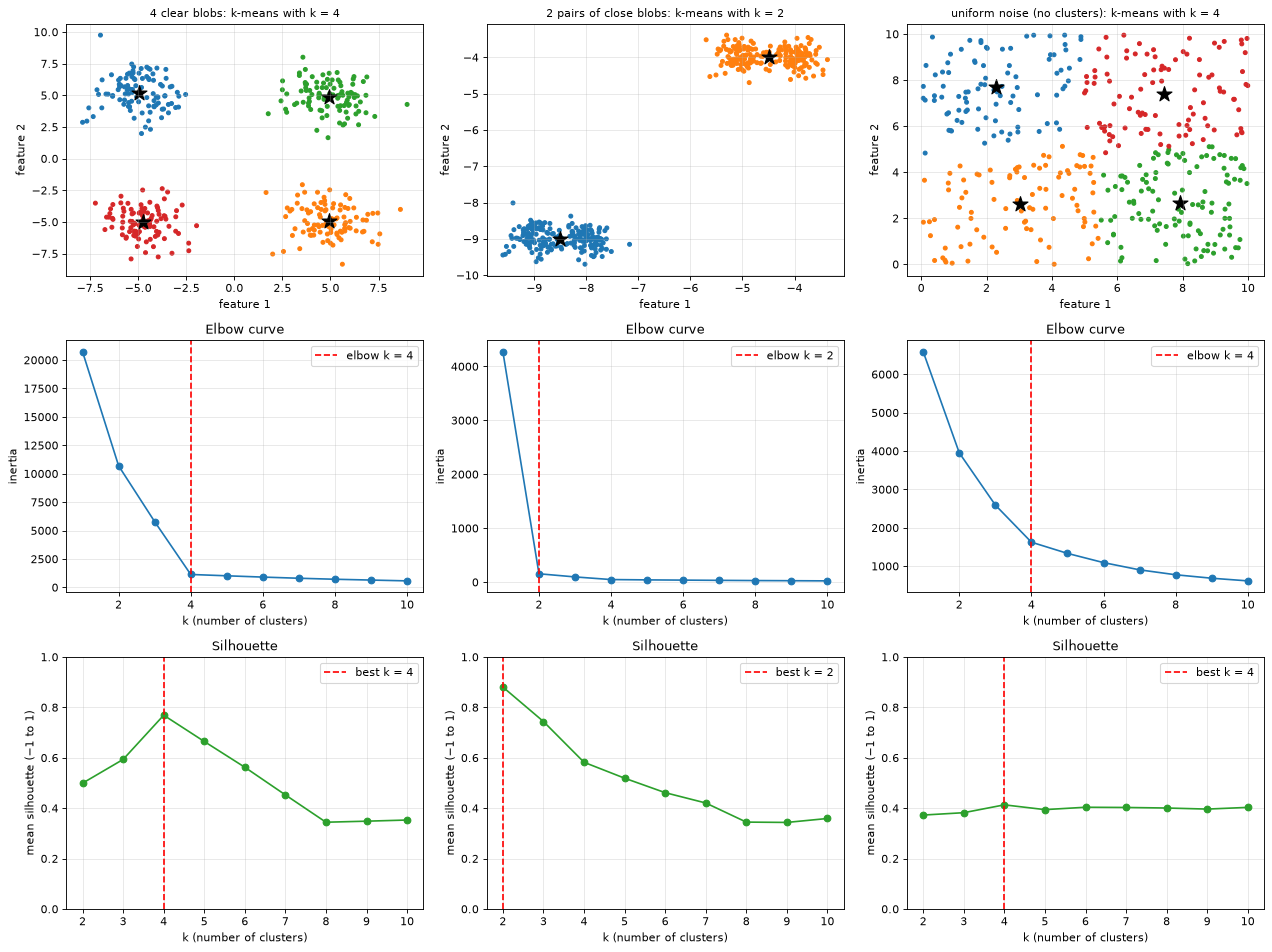

In [4]:
def knee_by_chord(ks, values):
    """The k whose point lies farthest from the straight line joining the first and last points of the curve
    (the 'kneedle' idea): where the curve bends most."""
    ks, values = np.asarray(ks, float), np.asarray(values, float)
    x = (ks - ks[0]) / (ks[-1] - ks[0]); v = (values - values.min()) / (values.max() - values.min())
    chord = v[0] + (v[-1] - v[0]) * x                                  # the straight line between the end points
    return int(ks[np.argmax(np.abs(chord - v))])


rng = np.random.default_rng(SEED)
k_sets = {
    "4 clear blobs": make_blobs(400, centers=[[-5, -5], [5, -5], [-5, 5], [5, 5]], cluster_std=1.2, random_state=1)[0],
    "2 pairs of close blobs": make_blobs(400, cluster_std=0.25, centers=[[-4, -4], [-5, -4], [-9, -9], [-8, -9]],
                                         random_state=1)[0],
    "uniform noise (no clusters)": rng.uniform(0, 10, size=(400, 2)),
}
ks = range(1, 11)
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for col, (name, X) in enumerate(k_sets.items()):
    inertia = [KMeans(k, n_init=10, random_state=SEED).fit(X).inertia_ for k in ks]
    sil = [silhouette_score(X, KMeans(k, n_init=10, random_state=SEED).fit_predict(X)) for k in ks[1:]]
    k_elbow, k_sil = knee_by_chord(ks, inertia), ks[1:][int(np.argmax(sil))]
    print(f"{name:28s} elbow (chord) k = {k_elbow}, best silhouette k = {k_sil} ({max(sil):.2f}); "
          f"silhouette at k=2..5: {np.round(sil[:4], 2)}")
    km = KMeans(k_sil, n_init=10, random_state=SEED).fit(X)
    plot_clusters(axes[0, col], X, km.labels_, f"{name}: k-means with k = {k_sil}", km.cluster_centers_)
    axes[1, col].plot(ks, inertia, marker="o"); axes[1, col].axvline(k_elbow, color="red", ls="--", label=f"elbow k = {k_elbow}")
    axes[1, col].set_xlabel("k (number of clusters)"); axes[1, col].set_ylabel("inertia"); axes[1, col].legend()
    axes[1, col].set_title("Elbow curve")
    axes[2, col].plot(ks[1:], sil, marker="o", color="tab:green")
    axes[2, col].axvline(k_sil, color="red", ls="--", label=f"best k = {k_sil}")
    axes[2, col].set_xlabel("k (number of clusters)"); axes[2, col].set_ylabel("mean silhouette (−1 to 1)")
    axes[2, col].set_ylim(0, 1); axes[2, col].legend(); axes[2, col].set_title("Silhouette")
plt.tight_layout(); plt.show()

> **How to read this**
> * **4 clear blobs:** both methods say **k = 4** (silhouette **0.77**, clearly above k = 3's 0.59 and k = 5's 0.66).
>   When clusters are well separated, the methods agree with the truth.
> * **2 pairs of close blobs:** both say **k = 2** (silhouette **0.88**; k = 4 gets only 0.58), although the data was
>   generated from 4 centres. Both answers are defensible: at a coarse scale there are 2 groups, at a fine scale 4.
>   Scores that compare k values pick the *coarsest* clear structure; a dendrogram ([Lab 5](../02-hierarchical/hierarchical_lab.ipynb#lab-5)) shows both levels.
> * **Uniform noise:** k-means happily cuts it into k = 4 pieces and both methods "choose" 4, but the best silhouette
>   is only **0.41**, against 0.77 and 0.88 for real clusters. k-means always returns clusters; a low silhouette at
>   every k is the warning sign that there may be none.
> * In practice: look at several k, prefer methods that agree, and judge whether the clusters mean something.

<a id="lab-4"></a>

## Lab 4 · Where k-means fails

**Goal:** k-means assigns every point to its **nearest centroid**, so it draws straight borders halfway between
centroids and works best for round clusters of similar size and spread (README §3.6). Test it on the six shapes from
scikit-learn's comparison gallery, with the **true** number of clusters given, plus a dataset with three far outliers.

k-means with the true number of clusters; ARI = agreement with the true groups (1 = perfect, 0 = chance)
  round blobs      ARI 1.00
  stretched blobs  ARI 0.56
  unequal spreads  ARI 0.79
  unequal sizes    ARI 0.88
  moons            ARI 0.25
  circles          ARI -0.00
  3 blobs + 3 far outliers, k = 3: cluster sizes [200   3 100]


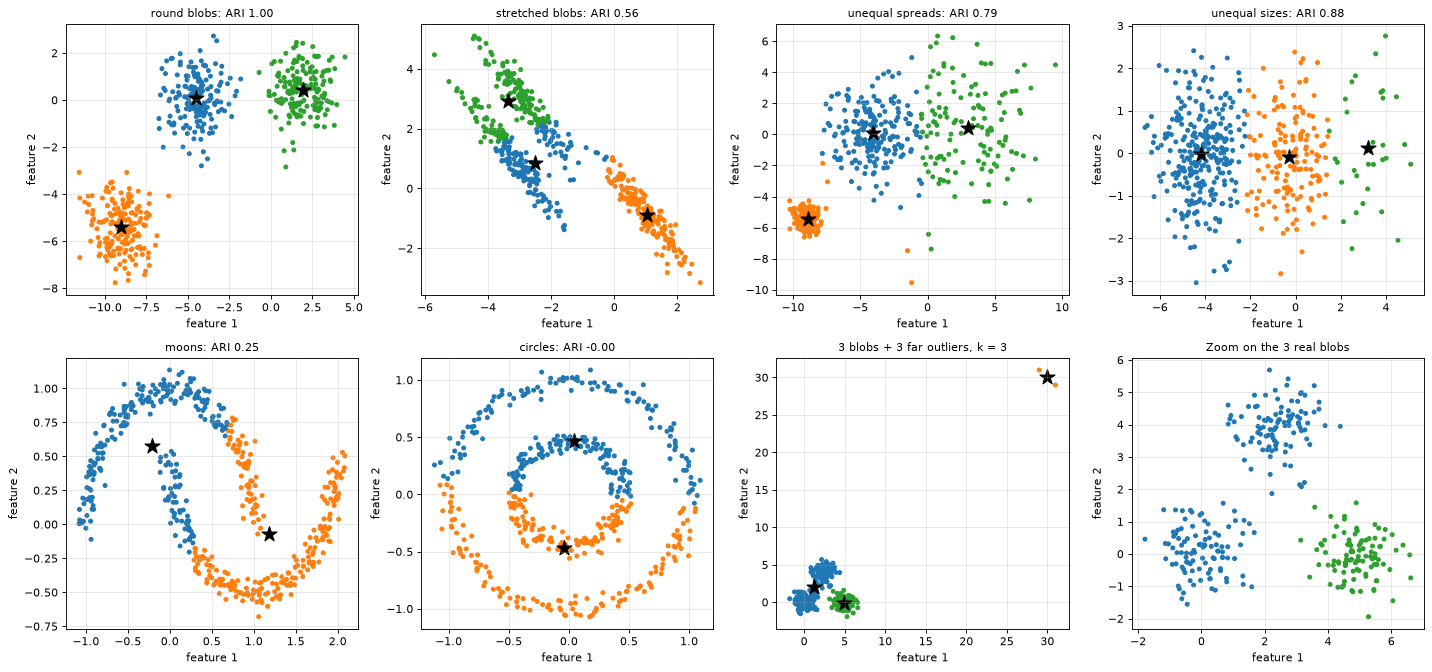

In [5]:
X_out, y_out = make_blobs(300, centers=[[0, 0], [5, 0], [2.5, 4]], cluster_std=0.7, random_state=SEED)
X_out = np.vstack([X_out, [[30, 30], [31, 29], [29, 31]]])            # three far-away outliers
y_out = np.append(y_out, [3, 3, 3])

fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
print("k-means with the true number of clusters; ARI = agreement with the true groups (1 = perfect, 0 = chance)")
for ax, (name, (X, y, k)) in zip(axes.flat, shapes.items()):
    km = KMeans(k, n_init=10, random_state=SEED).fit(X)
    ari = adjusted_rand_score(y, km.labels_)
    print(f"  {name:16s} ARI {ari:.2f}")
    plot_clusters(ax, X, km.labels_, f"{name}: ARI {ari:.2f}", km.cluster_centers_)
km_out = KMeans(3, n_init=10, random_state=SEED).fit(X_out)
print(f"  3 blobs + 3 far outliers, k = 3: cluster sizes {np.bincount(km_out.labels_)}")
plot_clusters(axes[1, 2], X_out, km_out.labels_, "3 blobs + 3 far outliers, k = 3", km_out.cluster_centers_)
plot_clusters(axes[1, 3], X_out[:300], km_out.labels_[:300], "Zoom on the 3 real blobs")
plt.tight_layout(); plt.show()

> **How to read this**
> * **Round blobs: ARI 1.00.** This is the shape k-means assumes.
> * **Stretched blobs: 0.56.** The same blobs, sheared. A nearest-centroid border is a straight line halfway between two
>   centroids, so long, tilted clusters get cut across.
> * **Unequal spreads: 0.79** and **unequal sizes: 0.88.** The border sits halfway between centroids regardless of how
>   wide or big each cluster is, so the large or wide cluster loses its edge points to its neighbour.
> * **Moons: 0.25, circles: −0.00.** Non-convex shapes can't be separated by straight borders at all: k-means cuts the
>   circles in half, top and bottom.
> * **Outliers:** with k = 3 the cluster sizes are **200 / 3 / 100**. The three far points got a cluster to themselves
>   (one centroid sitting on them is the cheapest way to cover their huge squared distances), so two real blobs had to
>   share one centroid (bottom right). Every point is assigned somewhere; k-means has no notion of noise.
> * Parts B and C use methods that don't assume round clusters.

---

<a id="summary"></a>

# Summary — what each lab showed

| Lab | Claim from the README | Verdict |
|---|---|---|
| [1](#lab-1) | k-means alternates assign / move and the inertia never rises | ✔ 4756.7 → 1718.5 in 15 steps |
| [2](#lab-2) | The start matters; k-means++ fixes most bad starts | ✔ 3 % vs 50 % of runs reach the best |
| [3](#lab-3) | Elbow and silhouette pick k | ✔ on clear blobs; picks the coarse level (2 of 4); "finds" 4 in pure noise (silhouette 0.41) |
| [4](#lab-4) | k-means assumes round, similar clusters and has no noise | ✘ stretched 0.56, moons 0.25, circles 0.00; 3 outliers steal a cluster |